# Do CV-parser errors reach the selection? A fairness audit of the Adecco reverse matching

**AI Ethics, Module 2 – Hiring CV Bias** · Francesco Baiocchi, Leonardo Petrilli

## Phase 3 – Do the parser's errors reach the selection? (RQ1)

Phase 2 (`phase2_protocol`) fixed the outcome: a candidate is selected for a job if they are in the top half of the
job's candidates, ranked by score, with ties drawn at random. Here we compare the selection made with the parser's
profile (O) and with the corrected one (C), group by group:

* **3.1** What does the correction change, and for which groups?
* **3.2** Independence: are all groups selected at the same rate?
* **3.3** Separation: does the parser make the same errors (false negatives, false positives) in every group?
* **3.4** Does the answer hold for a stricter selection, the top 3?

The groups are the values of the sensitive attributes `Gender`, `Location` and their intersection `group`. Each group
is compared with a reference group, which plays the role of the privileged group in the metrics: `Male`, `NORTH` and
`Male_NORTH`. Adecco's score appears only in 3.2, as the real system: it was computed on the profile P, partly entered
by hand (phase 1, section 1.4), so it cannot show the effect of the parser.

All shares in the tables are percentages.

In [ ]:
%load_ext autoreload
%autoreload 2

import warnings

import matplotlib.pyplot as plt
import polars as pl

%matplotlib inline
warnings.filterwarnings("ignore")

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_tbl_hide_dataframe_shape(True)

polars.config.Config

In [ ]:
from hiring_cv_bias.fairness.protocol import (
    SCORES,
    add_outcomes,
    filter_protocol,
    load_pairs,
)

df = add_outcomes(filter_protocol(load_pairs()), SCORES)
print(f"protocol pairs: {df.height:,}, candidates: {df['CANDIDATE_ID'].n_unique():,}")

protocol pairs: 36,760, candidates: 6,510


### 3.1 What the correction changes

We follow the correction in three steps: the candidates, their pairs, and the pairs whose outcome changes.

**Candidates.** For each field read by the parser (licenses, languages, job titles in `experience`), the table counts
the candidates who get at least one item the parser had missed, their share of the 6,510 protocol candidates, and the
items added in all.

In [ ]:
from hiring_cv_bias.fairness.metrics import for_display, profile_corrections
from hiring_cv_bias.reverse_matching.build import profile_path

profiles = {v: pl.read_parquet(profile_path(v)) for v in "OC"}
corrections = profile_corrections(
    profiles["O"], profiles["C"], df["CANDIDATE_ID"].unique()
)
display(for_display(corrections))

field,candidates_corrected,share_of_candidates,items_added
"""licenses""",2174,33.4,2174
"""languages""",2675,41.1,4833
"""experience""",3066,47.1,4830


Job titles are corrected for the most candidates (47.1%), then languages (41.1%) and licenses (33.4%). A corrected
candidate gets exactly one license, but more than one language or title on average (4,833 languages for 2,675
candidates, 4,830 titles for 3,066).

**Pairs.** A candidate has one pair per job. For each group, the table gives the share of its pairs where the
correction changes `Card_match`, `Languages_match`, the estimated `Experience` (by more than 0.01) and the score.

In [ ]:
from hiring_cv_bias.fairness.metrics import parser_changes

display(for_display(parser_changes(df)))

attribute,group,pairs,Card_match,Languages_match,Experience,score
"""Gender""","""Female""",17489,9.1,6.8,10.3,25.4
"""Gender""","""Male""",19271,9.4,6.5,13.0,27.5
"""Location""","""NORTH""",29144,9.7,6.6,11.3,26.5
"""Location""","""CENTER""",3300,8.6,7.3,12.4,27.2
"""Location""","""SOUTH""",4316,6.8,6.4,14.0,26.0
"""group""","""Female_NORTH""",13798,9.6,7.2,10.4,25.9
"""group""","""Male_NORTH""",15346,9.8,6.1,12.2,27.1
"""group""","""Female_CENTER""",1669,7.5,5.6,8.9,23.1
"""group""","""Male_CENTER""",1631,9.6,9.0,16.0,31.5
"""group""","""Female_SOUTH""",2022,7.0,5.6,11.4,24.4


A license or a language counts only when the job asks for it (phase 1, section 1.2), so `Card_match` and
`Languages_match` change in at most 9.8% and 9.0% of a group's pairs. The score changes in about one pair in four in
every group, from 23.1% (`Female_CENTER`) to 31.5% (`Male_CENTER`). The South has fewer `Card_match` changes than the
North (6.8% against 9.7%) and more `Experience` changes (14.0% against 11.3%). This table has no intervals: whether such
differences reach the selection is measured in 3.2 and 3.3.

**Pairs that change outcome.** Now we keep only the pairs whose outcome changes from O to C (`changed_pairs`). The
columns are the same as above, but each share is among these pairs (a pair can have more than one change).
`score_unchanged` is the share whose own score does not change at all.

In [ ]:
from hiring_cv_bias.fairness.metrics import SCORE_CHANGED, outcome_change_sources

display(for_display(outcome_change_sources(df)))
changed = df.filter(pl.col("top_half_O") != pl.col("top_half_C"))
same_score = changed.filter(~SCORE_CHANGED)
print(
    f"pairs whose outcome changes: {changed.height:,} of {df.height:,} "
    f"({changed.height / df.height:.1%})"
)
print(
    f"  with the same score: {same_score.height:,} "
    f"({same_score['top_half_C'].sum()} enter the top half, "
    f"{(~same_score['top_half_C']).sum():,} leave it)"
)
print(f"pairs whose score goes down with C: {(df['score_C'] < df['score_O']).sum()}")

attribute,group,changed_pairs,Card_match,Languages_match,Experience,score_unchanged
"""Gender""","""Female""",1375,19.3,11.6,32.5,45.3
"""Gender""","""Male""",1653,17.1,9.4,39.4,43.3
"""Location""","""NORTH""",2284,19.0,10.6,35.9,44.1
"""Location""","""CENTER""",287,13.2,13.6,40.8,42.5
"""Location""","""SOUTH""",457,16.6,7.7,35.7,45.7
"""group""","""Female_NORTH""",1039,20.8,12.4,31.9,44.4
"""group""","""Male_NORTH""",1245,17.5,9.0,39.2,43.9
"""group""","""Female_CENTER""",108,10.2,14.8,38.9,45.4
"""group""","""Male_CENTER""",179,15.1,12.8,41.9,40.8
"""group""","""Female_SOUTH""",228,16.7,6.1,32.5,49.6


pairs whose outcome changes: 3,028 of 36,760 (8.2%)
  with the same score: 1,339 (0 enter the top half, 1,339 leave it)
pairs whose score goes down with C: 0


The correction changes the outcome of 3,028 pairs, 8.2% of the total. In every group the most common cause is a new
job title (`Experience`, 31.9% to 41.9% of the changed pairs), then a license (10.2% to 20.8%) and a language (6.1% to
14.8%).

Almost half of these pairs change nothing of their own: 1,339 of the 3,028 (40.8% to 49.6% per group) keep the same
score. The correction only adds information, so no score goes down, and all 1,339 leave the top half. They are
candidates overtaken by a competitor of the same job whose CV was corrected: with O they had a place only because the
parser had missed something in that competitor's CV.

### 3.2 Independence: selection rates per group

Independence (statistical parity) asks the selection rate P(D = 1 | A = a) to be the same in every group a, where
D = 1 means selected and A is the sensitive attribute. For each score we compare every group with its reference group
in two ways:

* `spd_<score>`, the statistical parity difference: the group's rate minus the reference rate (0 means parity);
* `di_<score>`, the disparate impact: the group's rate divided by the reference rate (1 means parity).

Rates are computed over pairs, the unit fixed in phase 2: each pair is one decision, so a candidate who appears in
several jobs counts once for each job.

**Intervals.** A group has a few hundred to a few thousand candidates, so its numbers are uncertain. We measure this
with a bootstrap: 1,000 times, we draw the candidates again with replacement (a candidate drawn twice counts twice),
draw the ties again and recompute every number. The 95% interval holds the middle 95% of the 1,000 values. We draw
candidates, not pairs: the pairs of a candidate share the same profile and group, so they are not independent, and
drawing them one by one would count them as separate evidence and make the intervals too narrow. If the interval of an
SPD contains 0, or that of a DI contains 1, the data show no difference.

The tables write a number with its interval as `value [low, high]`; SPD is in percentage points, DI is a ratio. The
figure shows the rates with their intervals; the dashed line is the rate of all pairs.

In [ ]:
from hiring_cv_bias.fairness.metrics import bootstrap, parser_effect, selection_rates

results = bootstrap(
    df,
    {
        "rates": selection_rates,
        "effect": parser_effect,
        "effect_top3": lambda d: parser_effect(d, outcome="top3"),
    },
    n_boot=1000,
)

attribute,group,pairs,spd_adecco,spd_O,spd_C,di_adecco,di_O,di_C
"""Gender""","""Female""",17489,"""-0.7 [-2.6, 1.2]""","""-0.8 [-2.8, 1.1]""","""-1.2 [-3.2, 0.8]""","""0.99 [0.95, 1.02]""","""0.99 [0.95, 1.02]""","""0.98 [0.94, 1.01]"""
"""Gender""","""Male""",19271,"""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""1.0 [1.0, 1.0]""","""1.0 [1.0, 1.0]""","""1.0 [1.0, 1.0]"""
"""Location""","""NORTH""",29144,"""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""1.0 [1.0, 1.0]""","""1.0 [1.0, 1.0]""","""1.0 [1.0, 1.0]"""
"""Location""","""CENTER""",3300,"""1.0 [-2.0, 4.2]""","""1.3 [-2.3, 4.7]""","""1.2 [-2.1, 4.5]""","""1.02 [0.96, 1.08]""","""1.02 [0.96, 1.09]""","""1.02 [0.96, 1.09]"""
"""Location""","""SOUTH""",4316,"""-0.2 [-2.9, 2.5]""","""-0.2 [-3.1, 2.8]""","""-0.2 [-3.1, 2.7]""","""1.0 [0.94, 1.05]""","""1.0 [0.94, 1.05]""","""1.0 [0.94, 1.05]"""
"""group""","""Female_NORTH""",13798,"""-0.8 [-2.7, 1.4]""","""-1.2 [-3.4, 1.1]""","""-1.4 [-3.7, 0.8]""","""0.98 [0.95, 1.03]""","""0.98 [0.94, 1.02]""","""0.97 [0.93, 1.02]"""
"""group""","""Male_NORTH""",15346,"""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""1.0 [1.0, 1.0]""","""1.0 [1.0, 1.0]""","""1.0 [1.0, 1.0]"""
"""group""","""Female_CENTER""",1669,"""-1.1 [-5.2, 3.5]""","""0.9 [-3.8, 5.5]""","""-0.1 [-4.8, 4.3]""","""0.98 [0.9, 1.07]""","""1.02 [0.93, 1.11]""","""1.0 [0.91, 1.08]"""
"""group""","""Male_CENTER""",1631,"""2.3 [-2.6, 6.9]""","""0.5 [-4.5, 5.4]""","""1.3 [-3.6, 6.0]""","""1.04 [0.95, 1.13]""","""1.01 [0.91, 1.1]""","""1.03 [0.93, 1.11]"""
"""group""","""Female_SOUTH""",2022,"""0.4 [-4.1, 3.5]""","""-0.1 [-4.6, 3.3]""","""-0.8 [-4.9, 3.0]""","""1.01 [0.92, 1.07]""","""1.0 [0.91, 1.06]""","""0.98 [0.91, 1.06]"""


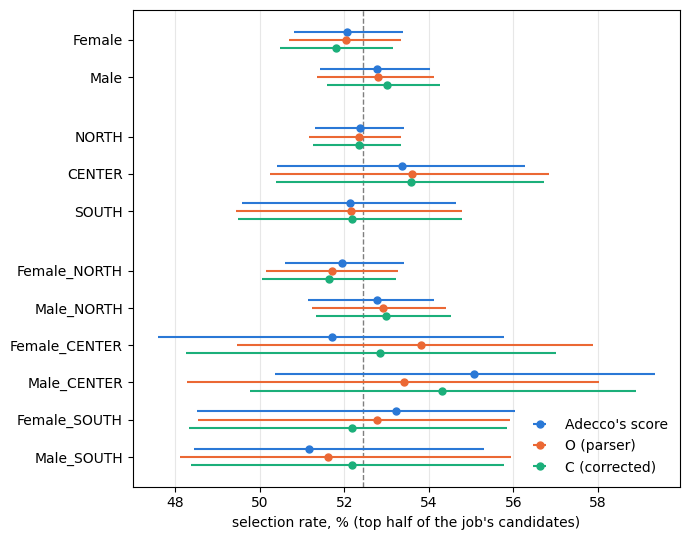

In [ ]:
from hiring_cv_bias.fairness.plots import plot_selection_rates

rates = results["rates"]
versions = ["adecco", "O", "C"]
display(
    for_display(
        rates, [f"spd_{v}" for v in versions], ratios=[f"di_{v}" for v in versions]
    )
)
plot_selection_rates(rates, overall=df["top_half_O"].mean())
plt.show()

Every SPD is between −1.6 and +2.3 points and every DI between 0.97 and 1.04, with Adecco's score, with O and with C;
every SPD interval contains 0 and every DI interval contains 1. Women are selected 0.7 points less often than men
with Adecco's score, 0.8 with O and 1.2 with C (DI 0.99, 0.99 and 0.98). The lowest bound of any DI is 0.90, well
above the 0.8 of the four-fifths rule. The data show no violation of independence, before or after the correction.

### 3.3 Separation: the parser's errors per group

To measure the parser's errors we take the outcome with the corrected profile as the label Y and the outcome with the
parser's profile as the decision D. C is not the truth: it holds what our extractors recovered from the CV text, so
the errors below are errors of O relative to C.

* **False negative** (D = 0, Y = 1): a pair selected with C that O leaves out. `fnr` = P(D = 0 | Y = 1, A = a).
* **False positive** (D = 1, Y = 0): a pair that O selects and C does not. `fpr` = P(D = 1 | Y = 0, A = a).

Separation (equalized odds) asks both rates to be the same in every group: `fnr_diff` and `fpr_diff` are the gaps from
the reference group. `rate_change`, the rate with C minus the rate with O, tells whether a group gains places when the
parser is corrected. Every job selects the same number of candidates with O and with C, so a group can have
`rate_change` = 0 and still many errors, if it has as many false negatives as false positives. The figure shows
`rate_change` and the two gaps; the dashed line is 0.

attribute,group,pairs,rate_change,fnr,fpr,fnr_diff,fpr_diff
"""Gender""","""Female""",17489,"""-0.2 [-0.9, 0.5]""","""7.4 [6.3, 8.4]""","""8.4 [7.5, 9.1]""","""-0.9 [-2.4, 0.6]""","""-0.5 [-1.7, 0.5]"""
"""Gender""","""Male""",19271,"""0.2 [-0.5, 0.9]""","""8.3 [7.1, 9.3]""","""8.9 [8.1, 9.7]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""NORTH""",29144,"""0.0 [-0.5, 0.6]""","""7.5 [6.7, 8.3]""","""8.2 [7.6, 8.8]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""CENTER""",3300,"""0.0 [-1.8, 1.9]""","""8.1 [5.7, 10.9]""","""9.4 [7.4, 11.8]""","""0.6 [-2.0, 3.4]""","""1.2 [-0.9, 3.8]"""
"""Location""","""SOUTH""",4316,"""0.0 [-1.4, 1.6]""","""10.2 [8.1, 12.7]""","""11.0 [9.1, 13.1]""","""2.7 [0.5, 5.4]""","""2.8 [0.9, 4.9]"""
"""group""","""Female_NORTH""",13798,"""-0.1 [-0.8, 0.7]""","""7.2 [6.1, 8.3]""","""7.9 [7.0, 8.6]""","""-0.5 [-2.1, 1.0]""","""-0.7 [-1.8, 0.6]"""
"""group""","""Male_NORTH""",15346,"""0.1 [-0.7, 0.9]""","""7.7 [6.5, 9.0]""","""8.6 [7.6, 9.3]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""group""","""Female_CENTER""",1669,"""-1.0 [-3.2, 1.3]""","""5.2 [2.5, 8.7]""","""7.9 [5.1, 11.3]""","""-2.5 [-5.7, 1.0]""","""-0.7 [-3.6, 3.1]"""
"""group""","""Male_CENTER""",1631,"""0.9 [-2.0, 4.2]""","""10.9 [6.9, 15.3]""","""11.0 [7.7, 15.0]""","""3.2 [-0.9, 7.8]""","""2.5 [-0.9, 6.6]"""
"""group""","""Female_SOUTH""",2022,"""-0.6 [-2.2, 2.1]""","""10.2 [7.5, 13.8]""","""12.4 [9.0, 14.7]""","""2.5 [-0.5, 6.4]""","""3.9 [0.3, 6.4]"""


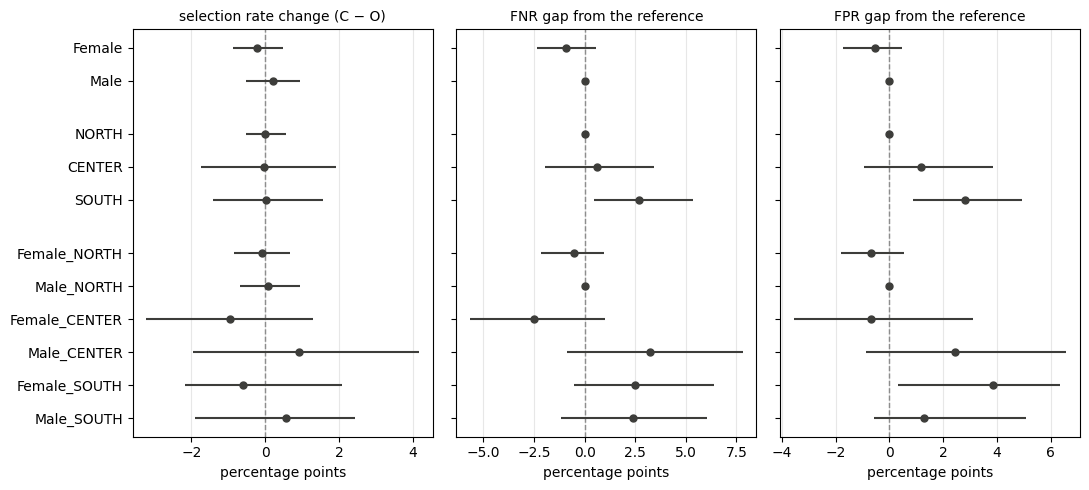

In [ ]:
from hiring_cv_bias.fairness.plots import plot_parser_effect

effect = results["effect"]
display(for_display(effect, ["rate_change", "fnr", "fnr_diff", "fpr", "fpr_diff"]))
plot_parser_effect(effect)
plt.show()

**Places.** Every `rate_change` interval contains 0; the largest values are −1.0 points for `Female_CENTER` and +0.9
for `Male_CENTER`. Correcting the parser does not move places from one group to another.

**Errors.** The South is the only area where the parser's errors differ from the North, and in both directions:

* FNR: O leaves out 10.2% of the southern pairs selected with C, against 7.5% in the North (gap 2.7 points, interval
  0.5 to 5.4);
* FPR: O selects 11.0% of the southern pairs not selected with C, against 8.2% (gap 2.8, interval 0.9 to 4.9).

False negatives and false positives cancel in the count, so `rate_change` is 0, but more southern decisions are wrong.
Among the six intersectional groups, the only gap whose interval excludes 0 is the FPR of `Female_SOUTH`: 12.4%
against 8.6% for `Male_NORTH` (gap 3.9, interval 0.3 to 6.4). Between women and men there is no gap.

### 3.4 The same with the top 3

A stricter selection: the first three candidates of every job. The table repeats `rate_change`, `fnr_diff` and
`fpr_diff` of 3.3 with `top3` as the outcome.

In [ ]:
display(for_display(results["effect_top3"], ["rate_change", "fnr_diff", "fpr_diff"]))

attribute,group,pairs,rate_change,fnr_diff,fpr_diff
"""Gender""","""Female""",17489,"""0.3 [-0.3, 0.9]""","""-0.5 [-2.6, 2.0]""","""-0.8 [-1.6, -0.1]"""
"""Gender""","""Male""",19271,"""-0.3 [-0.9, 0.4]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""NORTH""",29144,"""0.0 [-0.5, 0.4]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""CENTER""",3300,"""0.0 [-1.9, 1.8]""","""1.9 [-2.4, 6.7]""","""2.0 [0.5, 3.9]"""
"""Location""","""SOUTH""",4316,"""0.0 [-1.3, 1.2]""","""4.4 [0.3, 8.3]""","""0.5 [-0.5, 1.5]"""
"""group""","""Female_NORTH""",13798,"""0.3 [-0.3, 1.0]""","""0.4 [-2.0, 2.9]""","""-0.6 [-1.4, 0.2]"""
"""group""","""Male_NORTH""",15346,"""-0.3 [-0.9, 0.4]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""group""","""Female_CENTER""",1669,"""-0.2 [-2.1, 2.1]""","""-2.1 [-6.7, 3.6]""","""0.1 [-1.7, 2.0]"""
"""group""","""Male_CENTER""",1631,"""0.2 [-3.2, 3.6]""","""6.4 [-0.5, 13.7]""","""3.3 [0.8, 6.8]"""
"""group""","""Female_SOUTH""",2022,"""0.3 [-1.4, 2.2]""","""5.2 [-0.5, 11.3]""","""-0.1 [-1.5, 1.4]"""


Every `rate_change` interval still contains 0, and the higher FNR of the South remains: 4.4 points more than the North
(interval 0.3 to 8.3). The higher FPR does not (0.5 points, interval −0.5 to 1.5). Three gaps exclude 0 here but not in
3.3: the FPR is higher for `CENTER` (2.0 points) and `Male_CENTER` (3.3), and lower for women (−0.8).

**Many comparisons.** 3.3 and 3.4 hold 32 gaps (8 groups × 2 error rates × 2 outcomes). At the 95% level, one or two
of them would exclude 0 by chance alone. So a gap seen with only one outcome is weak evidence; the one seen with both is
the higher FNR of the South.

### Findings for RQ1

* **The parser's errors reach the selection.** Correcting them changes the score of about one pair in four and the
  outcome of 8.2% of the pairs. A new job title is the most common cause, and almost half of the pairs that change
  outcome are candidates overtaken by a corrected competitor (3.1).
* **Independence is not violated.** No group is selected at a different rate from its reference group, with O or
  with C: every SPD interval contains 0 and every DI interval contains 1 (3.2). No group gains or loses places when the
  parser is corrected (3.3, 3.4).
* **Separation is violated for the South.** O has a higher false negative rate for southern pairs than for northern
  ones (10.2% against 7.5%) and a higher false positive rate (11.0% against 8.2%). The higher FNR holds with the top 3
  too (3.4).
* **No gender gap.** Women and men have the same error rates. Among the intersectional groups, women from the South
  have a higher FPR (3.3); the other gaps are within their intervals, which are wide for the smaller groups.